<a href="https://colab.research.google.com/github/Jeetansh-Ruhela/Minor-Project-05-By-Jeetansh-Ruhela/blob/main/Minor_Project_05%20By%20Jeetansh%20Ruhela%20AI%20OCT%20B%20Batch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Credit Card Customer Churn Prediction

## Minor Project – Machine Learning

### Problem Statement
Customer attrition is a major challenge for banking institutions. Identifying customers who are likely to discontinue their credit card services can help banks develop effective customer retention strategies.

### Project Objective
The objective of this project is to develop a machine learning model that predicts whether a credit card customer is likely to leave the bank.

### Dataset
- Source: Kaggle – Credit Card Customers Dataset
- Total Records: 10,127
- Original Features: 23 columns
- Target Variable: Attrition_Flag

### Technologies Used
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Google Colab

### Machine Learning Algorithms
1. AdaBoost Classifier
2. Random Forest Classifier
3. Tuned Random Forest using GridSearchCV

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score
)
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv('/content/BankChurners.csv')
df.head()

,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0.000093,0.99991
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0.000057,0.99994
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0.000021,0.99998
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,3,4,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,0.000134,0.99987
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000,0.000022,0.99998


In [3]:
print("Dataset Shape:", df.shape)
print("\nDataset Columns:")
print(df.columns.tolist())
print("\nDataset Information:")
df.info()
print("\nStatistical Summary:")
display(df.describe())
print("\nMissing Values:")
print(df.isnull().sum())
print("\nDuplicate Records:", df.duplicated().sum())

Dataset Shape: (10127, 23)

Dataset Columns:
['CLIENTNUM', 'Attrition_Flag', 'Customer_Age', 'Gender', 'Dependent_count', 'Education_Level', 'Marital_Status', 'Income_Category', 'Card_Category', 'Months_on_book', 'Total_Relationship_Count', 'Months_Inactive_12_mon', 'Contacts_Count_12_mon', 'Credit_Limit', 'Total_Revolving_Bal', 'Avg_Open_To_Buy', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt', 'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio', 'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1', 'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 23 columns):
 #   Column                                                                                                                              Non-N

,CLIENTNUM,Customer_Age,Dependent_count,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
count,1.012700e+04,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000
mean,7.391776e+08,46.325960,2.346203,35.928409,3.812580,2.341167,2.455317,8631.953698,1162.814061,7469.139637,0.759941,4404.086304,64.858695,0.712222,0.274894,0.159997,0.840003
std,3.690378e+07,8.016814,1.298908,7.986416,1.554408,1.010622,1.106225,9088.776650,814.987335,9090.685324,0.219207,3397.129254,23.472570,0.238086,0.275691,0.365301,0.365301
min,7.080821e+08,26.000000,0.000000,13.000000,1.000000,0.000000,0.000000,1438.300000,0.000000,3.000000,0.000000,510.000000,10.000000,0.000000,0.000000,0.000008,0.000420
25%,7.130368e+08,41.000000,1.000000,31.000000,3.000000,2.000000,2.000000,2555.000000,359.000000,1324.500000,0.631000,2155.500000,45.000000,0.582000,0.023000,0.000099,0.999660
50%,7.179264e+08,46.000000,2.000000,36.000000,4.000000,2.000000,2.000000,4549.000000,1276.000000,3474.000000,0.736000,3899.000000,67.000000,0.702000,0.176000,0.000181,0.999820
75%,7.731435e+08,52.000000,3.000000,40.000000,5.000000,3.000000,3.000000,11067.500000,1784.000000,9859.000000,0.859000,4741.000000,81.000000,0.818000,0.503000,0.000337,0.999900
max,8.283431e+08,73.000000,5.000000,56.000000,6.000000,6.000000,6.000000,34516.000000,2517.000000,34516.000000,3.397000,18484.000000,139.000000,3.714000,0.999000,0.999580,0.999990



Missing Values:
CLIENTNUM                                                                                                                             0
Attrition_Flag                                                                                                                        0
Customer_Age                                                                                                                          0
Gender                                                                                                                                0
Dependent_count                                                                                                                       0
Education_Level                                                                                                                       0
Marital_Status                                                                                                                        0
Income_Category                

In [4]:
data = df.copy()
data.drop(
    columns=[
        'CLIENTNUM',
        'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1',
        'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2'
    ],
    inplace=True
)
print("Updated Dataset Shape:", data.shape)
display(data.head())
print("\nRemaining Columns:")
print(data.columns.tolist())


Updated Dataset Shape: (10127, 20)


,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061
1,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105
2,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000
3,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,3,4,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760
4,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000



Remaining Columns:
['Attrition_Flag', 'Customer_Age', 'Gender', 'Dependent_count', 'Education_Level', 'Marital_Status', 'Income_Category', 'Card_Category', 'Months_on_book', 'Total_Relationship_Count', 'Months_Inactive_12_mon', 'Contacts_Count_12_mon', 'Credit_Limit', 'Total_Revolving_Bal', 'Avg_Open_To_Buy', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt', 'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio']


Attrition_Flag
Existing Customer    8500
Attrited Customer    1627
Name: count, dtype: int64


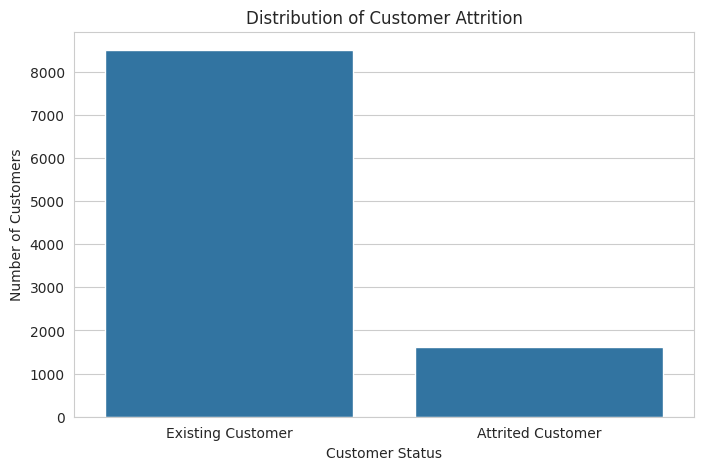

In [5]:
print(data['Attrition_Flag'].value_counts())
plt.figure(figsize=(8, 5))

sns.countplot(
    data=data,
    x='Attrition_Flag'
)
plt.title('Distribution of Customer Attrition')
plt.xlabel('Customer Status')
plt.ylabel('Number of Customers')
plt.show()

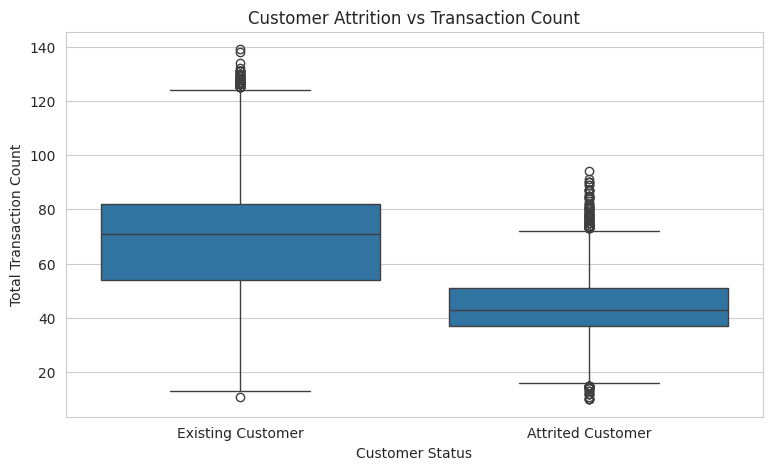

In [6]:
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=data,
    x='Attrition_Flag',
    y='Total_Trans_Ct'
)
plt.title('Customer Attrition vs Transaction Count')
plt.xlabel('Customer Status')
plt.ylabel('Total Transaction Count')
plt.show()

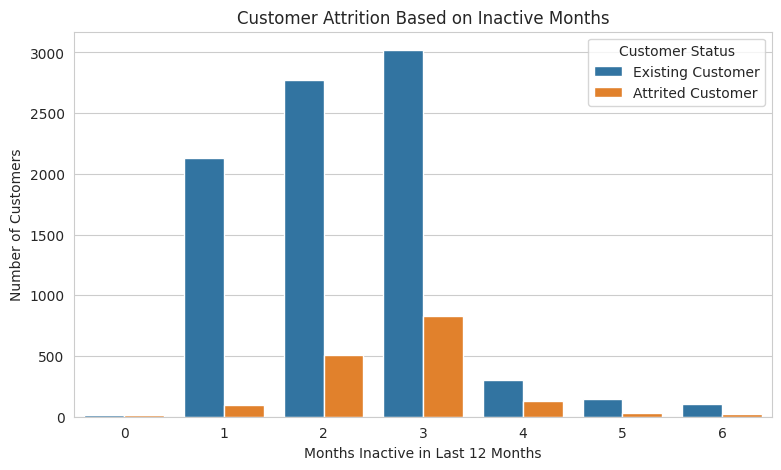

In [7]:
plt.figure(figsize=(9, 5))
sns.countplot(
    data=data,
    x='Months_Inactive_12_mon',
    hue='Attrition_Flag'
)
plt.title('Customer Attrition Based on Inactive Months')
plt.xlabel('Months Inactive in Last 12 Months')
plt.ylabel('Number of Customers')
plt.legend(title='Customer Status')
plt.show()

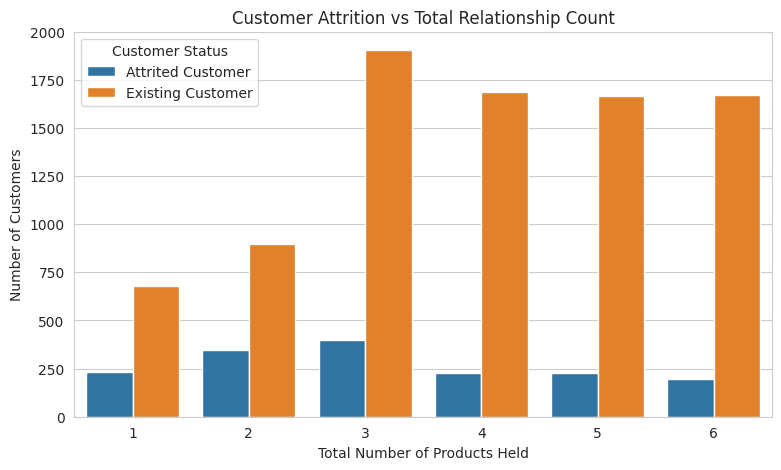

In [8]:
plt.figure(figsize=(9, 5))
sns.countplot(
    data=data,
    x='Total_Relationship_Count',
    hue='Attrition_Flag'
)
plt.title('Customer Attrition vs Total Relationship Count')
plt.xlabel('Total Number of Products Held')
plt.ylabel('Number of Customers')
plt.legend(title='Customer Status')
plt.show()

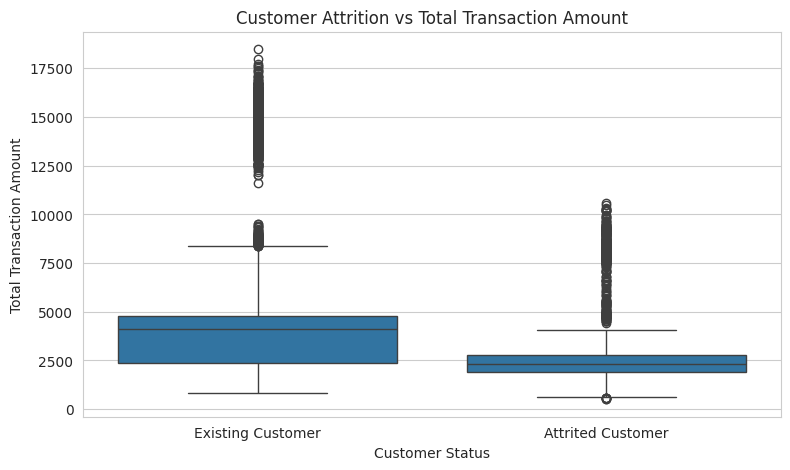

In [9]:
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=data,
    x='Attrition_Flag',
    y='Total_Trans_Amt'
)
plt.title('Customer Attrition vs Total Transaction Amount')
plt.xlabel('Customer Status')
plt.ylabel('Total Transaction Amount')
plt.show()


## Step 7: Additional Analysis – Customer Attrition Rate

To understand customer attrition more accurately, attrition
rates are calculated based on the number of inactive months
and the total number of products held by customers.


In [10]:
inactive_attrition = pd.crosstab(
    data['Months_Inactive_12_mon'],
    data['Attrition_Flag'],
    normalize='index'
) * 100
print("Attrition Rate Based on Inactive Months:")
display(inactive_attrition.round(2))
relationship_attrition = pd.crosstab(
    data['Total_Relationship_Count'],
    data['Attrition_Flag'],
    normalize='index'
) * 100
print("Attrition Rate Based on Relationship Count:")
display(relationship_attrition.round(2))

Attrition Rate Based on Inactive Months:


Attrition_Flag,Attrited Customer,Existing Customer
Months_Inactive_12_mon,,
0,51.72,48.28
1,4.48,95.52
2,15.39,84.61
3,21.48,78.52
4,29.89,70.11
5,17.98,82.02
6,15.32,84.68


Attrition Rate Based on Relationship Count:


Attrition_Flag,Attrited Customer,Existing Customer
Total_Relationship_Count,,
1,25.60,74.40
2,27.84,72.16
3,17.35,82.65
4,11.77,88.23
5,12.00,88.00
6,10.50,89.50



### Observations:

1. Customers inactive for 4 months show an attrition rate of 29.89%, indicating a possible relationship between inactivity and customer attrition.

2. Customers holding 2 banking products have the highest attrition rate (27.84%) among the relationship-count categories.

3. Customers holding 6 products have the lowest attrition rate (10.50%), suggesting that customers with more banking relationships may be less likely to leave.

4. Overall, customer inactivity and the number of banking products appear to be useful factors for understanding customer attrition.



## Step 8: Outlier Detection and Treatment

Outlier detection is performed to identify unusually high or low values in numerical features. Box plots and the Interquartile Range (IQR) method are used to identify potential outliers in the dataset.


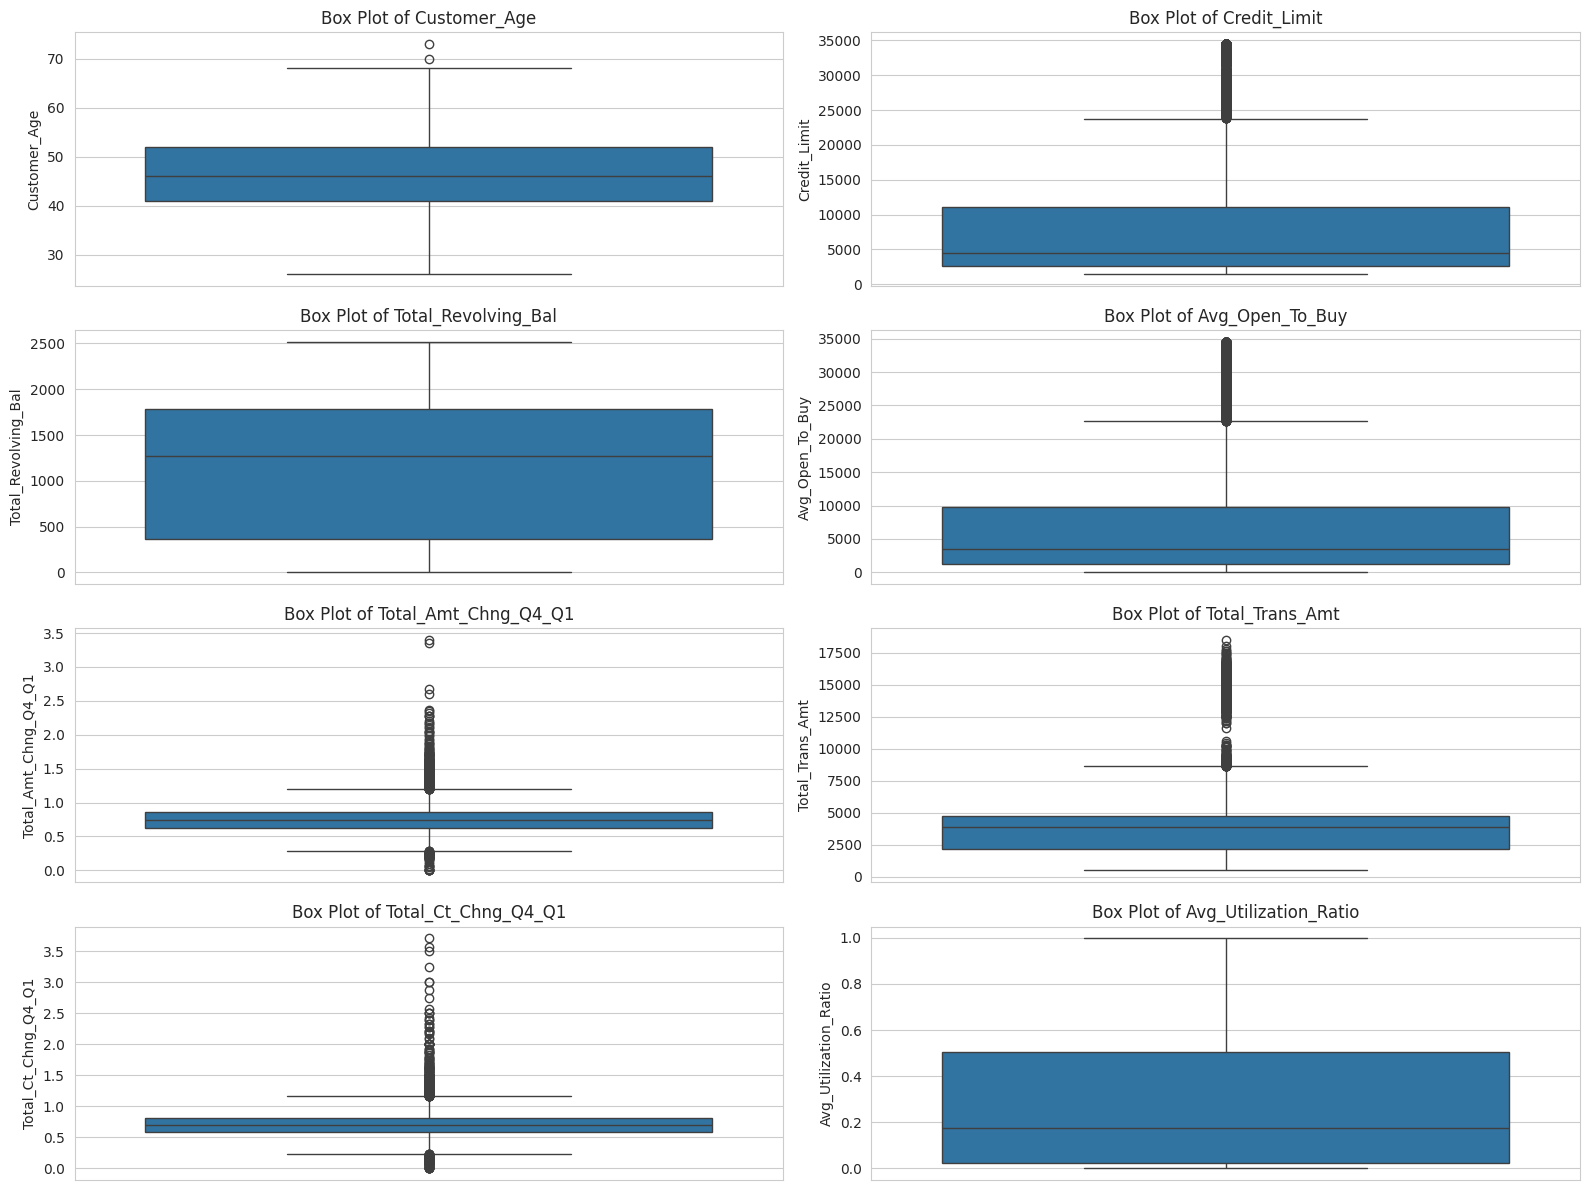

In [11]:

# Selecting numerical features for outlier detection

numerical_columns = [
    'Customer_Age',
    'Credit_Limit',
    'Total_Revolving_Bal',
    'Avg_Open_To_Buy',
    'Total_Amt_Chng_Q4_Q1',
    'Total_Trans_Amt',
    'Total_Ct_Chng_Q4_Q1',
    'Avg_Utilization_Ratio'
]

# Creating box plots
plt.figure(figsize=(16, 12))

for i, column in enumerate(numerical_columns, 1):
    plt.subplot(4, 2, i)
    sns.boxplot(y=data[column])
    plt.title(f'Box Plot of {column}')

plt.tight_layout()
plt.show()


In [12]:

# Detecting outliers using IQR method

outlier_summary = []

for column in numerical_columns:

    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = data[
        (data[column] < lower_limit) |
        (data[column] > upper_limit)
    ]

    outlier_summary.append({
        'Feature': column,
        'Lower Limit': lower_limit,
        'Upper Limit': upper_limit,
        'Outlier Count': len(outliers)
    })

outlier_df = pd.DataFrame(outlier_summary)

display(outlier_df)


,Feature,Lower Limit,Upper Limit,Outlier Count
0,Customer_Age,24.500,68.500,2
1,Credit_Limit,-10213.750,23836.250,984
2,Total_Revolving_Bal,-1778.500,3921.500,0
3,Avg_Open_To_Buy,-11477.250,22660.750,963
4,Total_Amt_Chng_Q4_Q1,0.289,1.201,396
5,Total_Trans_Amt,-1722.750,8619.250,896
6,Total_Ct_Chng_Q4_Q1,0.228,1.172,394
7,Avg_Utilization_Ratio,-0.697,1.223,0



### Observations:

1. Credit_Limit has the highest number of potential outliers, with 984 records.

2. Avg_Open_To_Buy and Total_Trans_Amt also contain a considerable number of potential outliers.

3. Customer_Age has only 2 potential outliers, while Total_Revolving_Bal and Avg_Utilization_Ratio have no outliers according to the IQR method.

### Outlier Treatment:

The identified outliers were examined and found to represent potentially valid customer information. Therefore, no records were removed or capped, as doing so could result in the loss of useful information. The original dataset values were retained for further analysis and model building.



## Step 9: Data Preprocessing

Data preprocessing is performed to prepare the dataset for machine learning. It involves separating the target variable from independent features, encoding categorical variables, and splitting the dataset into training and testing sets.



### 9.1 Separating Independent and Dependent Variables

The independent variables contain customer information and transaction details used for prediction, while the dependent variable represents the customer status (Existing or Attrited).


In [13]:

# Separating independent and dependent variables

X = data.drop('Attrition_Flag', axis=1)
y = data['Attrition_Flag']

# Displaying the shapes
print("Independent Variables Shape:", X.shape)
print("Dependent Variable Shape:", y.shape)

# Displaying target categories
print("\nTarget Variable Distribution:")
print(y.value_counts())


Independent Variables Shape: (10127, 19)
Dependent Variable Shape: (10127,)

Target Variable Distribution:
Attrition_Flag
Existing Customer    8500
Attrited Customer    1627
Name: count, dtype: int64



### 9.2 Identifying Numerical and Categorical Features

The independent variables are divided into numerical and categorical features. This helps us apply appropriate preprocessing techniques to each type of data.


In [14]:
# Identifying numerical and categorical columns

numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nNumber of Numerical Features:", len(numerical_features))
print("Number of Categorical Features:", len(categorical_features))


Numerical Features:
['Customer_Age', 'Dependent_count', 'Months_on_book', 'Total_Relationship_Count', 'Months_Inactive_12_mon', 'Contacts_Count_12_mon', 'Credit_Limit', 'Total_Revolving_Bal', 'Avg_Open_To_Buy', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt', 'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio']

Categorical Features:
['Gender', 'Education_Level', 'Marital_Status', 'Income_Category', 'Card_Category']

Number of Numerical Features: 14
Number of Categorical Features: 5



### 9.3 Encoding the Target Variable

The target variable contains categorical values representing customer status. These values are converted into numerical labels so that machine learning algorithms can process them.


In [15]:

# Encoding target variable

y = y.map({
    'Existing Customer': 0,
    'Attrited Customer': 1
})

print("Encoded Target Variable:")
print(y.value_counts())

print("\nUnique Target Values:", y.unique())


Encoded Target Variable:
Attrition_Flag
0    8500
1    1627
Name: count, dtype: int64

Unique Target Values: [0 1]



### 9.4 Train-Test Splitting

The dataset is divided into training and testing sets using an 80:20 ratio. The training set is used to train the machine learning models, while the testing set is used to evaluate their performance.

Stratified sampling is used to maintain the proportion of both customer classes in the training and testing sets.


In [16]:

# Splitting dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())


Training Data Shape: (8101, 19)
Testing Data Shape: (2026, 19)

Training Target Distribution:
Attrition_Flag
0    6799
1    1302
Name: count, dtype: int64

Testing Target Distribution:
Attrition_Flag
0    1701
1     325
Name: count, dtype: int64



### 9.5 Encoding Categorical Features

One-Hot Encoding is applied to categorical features to convert them into numerical representations. The handle_unknown='ignore' parameter ensures that previously unseen categories do not cause errors during prediction.


In [17]:

# Creating preprocessing pipeline

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'),
         categorical_features)
    ],
    remainder='passthrough'
)

print("Categorical Encoding Pipeline Created Successfully!")


Categorical Encoding Pipeline Created Successfully!



## Step 10: Machine Learning Model Building

### 10.1 AdaBoost Classifier

AdaBoost (Adaptive Boosting) is an ensemble machine learning algorithm that combines multiple weak learners to create a strong predictive model. It focuses on incorrectly classified observations during training to improve overall prediction performance.


In [18]:

# Building AdaBoost Classifier

from sklearn.ensemble import AdaBoostClassifier
from sklearn.pipeline import Pipeline

ada_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', AdaBoostClassifier(
        n_estimators=100,
        learning_rate=0.5,
        random_state=42
    ))
])

# Training the model
ada_pipeline.fit(X_train, y_train)

# Making predictions
ada_predictions = ada_pipeline.predict(X_test)

print("AdaBoost Model Trained Successfully!")


AdaBoost Model Trained Successfully!



### 10.2 Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines multiple decision trees to improve prediction accuracy and reduce overfitting. It uses the predictions of individual trees to generate the final classification result.


In [19]:

# Building Random Forest Classifier

rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight='balanced'
    ))
])

# Training the model
rf_pipeline.fit(X_train, y_train)

# Making predictions
rf_predictions = rf_pipeline.predict(X_test)

print("Random Forest Model Trained Successfully!")


Random Forest Model Trained Successfully!



### 10.3 Model Evaluation

The trained models are evaluated using accuracy, precision, recall and F1-score. These performance metrics help determine how effectively each model predicts customer attrition.


In [20]:

# Evaluating both models

models = {
    'AdaBoost': ada_predictions,
    'Random Forest': rf_predictions
}

results = []

for name, predictions in models.items():

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions),
        'Recall': recall_score(y_test, predictions),
        'F1 Score': f1_score(y_test, predictions)
    })

results_df = pd.DataFrame(results)

print("Model Performance Comparison:")
display(results_df.round(4))


Model Performance Comparison:


,Model,Accuracy,Precision,Recall,F1 Score
0,AdaBoost,0.9358,0.9295,0.6492,0.7645
1,Random Forest,0.9477,0.9261,0.7323,0.8179



### Observations:

1. AdaBoost achieved an accuracy of 93.58%, while Random Forest achieved 94.77%.

2. AdaBoost obtained slightly higher precision (92.95%) compared to Random Forest (92.61%).

3. Random Forest achieved a higher recall of 73.23%, indicating better identification of customers who are likely to leave.

4. Random Forest also achieved a higher F1-score of 81.79%, compared to 76.45% for AdaBoost.

### Conclusion:

Based on the evaluation metrics, Random Forest performed better overall than AdaBoost. Therefore, Random Forest is selected as the better-performing model for further hyperparameter tuning.



### 10.4 Classification Report and Confusion Matrix

A classification report provides detailed information about precision, recall, F1-score and support for each class. A confusion matrix helps visualize the correct and incorrect predictions made by the models.


AdaBoost Classification Report:
                   precision    recall  f1-score   support

Existing Customer       0.94      0.99      0.96      1701
Attrited Customer       0.93      0.65      0.76       325

         accuracy                           0.94      2026
        macro avg       0.93      0.82      0.86      2026
     weighted avg       0.94      0.94      0.93      2026


Random Forest Classification Report:
                   precision    recall  f1-score   support

Existing Customer       0.95      0.99      0.97      1701
Attrited Customer       0.93      0.73      0.82       325

         accuracy                           0.95      2026
        macro avg       0.94      0.86      0.89      2026
     weighted avg       0.95      0.95      0.95      2026



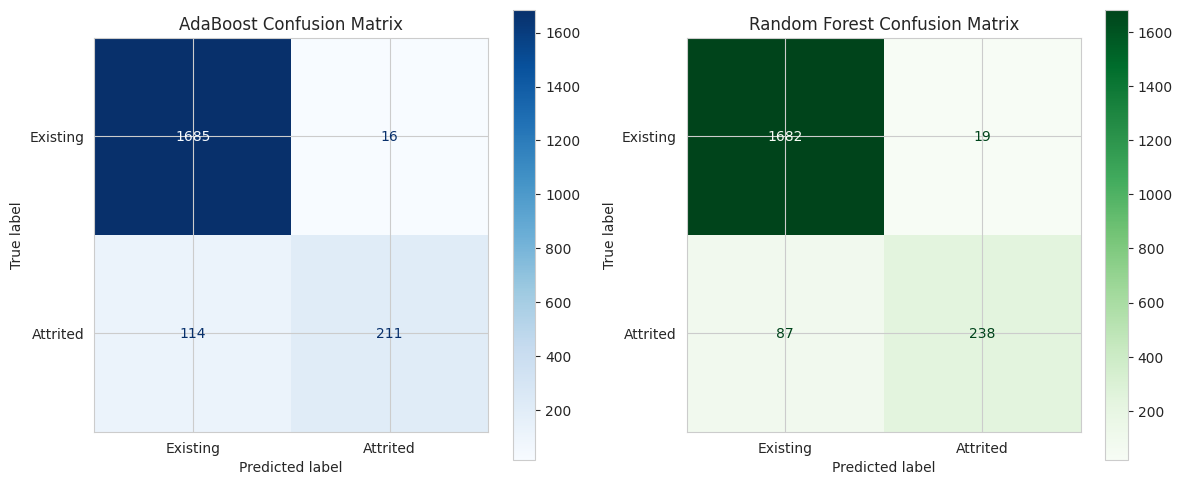

In [21]:

# Classification Reports

print("AdaBoost Classification Report:")
print(classification_report(
    y_test,
    ada_predictions,
    target_names=['Existing Customer', 'Attrited Customer']
))

print("\nRandom Forest Classification Report:")
print(classification_report(
    y_test,
    rf_predictions,
    target_names=['Existing Customer', 'Attrited Customer']
))


# Confusion Matrices

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    ada_predictions,
    display_labels=['Existing', 'Attrited'],
    cmap='Blues',
    ax=axes[0]
)

axes[0].set_title('AdaBoost Confusion Matrix')

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_predictions,
    display_labels=['Existing', 'Attrited'],
    cmap='Greens',
    ax=axes[1]
)

axes[1].set_title('Random Forest Confusion Matrix')

plt.tight_layout()
plt.show()



### Observations:

1. Both models demonstrate good overall classification performance.

2. AdaBoost achieves an F1-score of 0.76 for Attrited Customers, whereas Random Forest achieves 0.82.

3. Random Forest has a higher recall of 0.73 for Attrited Customers compared to 0.65 for AdaBoost.

4. Both models achieve approximately 0.99 recall for Existing Customers.

### Conclusion:

Based on the classification reports, Random Forest performs better in identifying attrited customers and achieves a higher F1-score. Therefore, Random Forest is considered the better-performing model before hyperparameter tuning.



### 10.5 Hyperparameter Tuning Using GridSearchCV

GridSearchCV is used to find the best combination of hyperparameters for the Random Forest classifier. It evaluates different parameter combinations using cross-validation to identify the best-performing configuration.


In [22]:

# Hyperparameter tuning using GridSearchCV

param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [10, 20, None],
    'classifier__min_samples_split': [2, 5],
    'classifier__min_samples_leaf': [1, 2]
}

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

# Training GridSearchCV
grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(grid_search.best_score_)


Fitting 3 folds for each of 24 candidates, totalling 72 fits
Best Parameters:
{'classifier__max_depth': 20, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 200}

Best Cross-Validation F1 Score:
0.8511713474472732


### Observations:

1. GridSearchCV evaluated 24 different hyperparameter combinations using 3-fold cross-validation.
2. The best configuration uses 200 decision trees with a maximum depth of 20.
3. The best cross-validation F1-score is 0.8512.
4. These optimized parameters will be used to evaluate the tuned Random Forest model on the test dataset.

In [23]:
# Get the best model from GridSearchCV
best_rf = grid_search.best_estimator_

# Make predictions on the test dataset
tuned_rf_predictions = best_rf.predict(X_test)

# Evaluate the tuned model
print("Tuned Random Forest Classification Report:")
print(classification_report(y_test, tuned_rf_predictions))

print("Tuned Random Forest Confusion Matrix:")
print(confusion_matrix(y_test, tuned_rf_predictions))

print("Tuned Random Forest Metrics:")
print("Accuracy:", accuracy_score(y_test, tuned_rf_predictions))
print("Precision:", precision_score(y_test, tuned_rf_predictions))
print("Recall:", recall_score(y_test, tuned_rf_predictions))
print("F1 Score:", f1_score(y_test, tuned_rf_predictions))

Tuned Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.98      0.97      1701
           1       0.89      0.81      0.85       325

    accuracy                           0.95      2026
   macro avg       0.93      0.90      0.91      2026
weighted avg       0.95      0.95      0.95      2026

Tuned Random Forest Confusion Matrix:
[[1670   31]
 [  62  263]]
Tuned Random Forest Metrics:
Accuracy: 0.9540967423494571
Precision: 0.8945578231292517
Recall: 0.8092307692307692
F1 Score: 0.8497576736672051


In [24]:
comparison = pd.DataFrame({
    'Model': ['AdaBoost', 'Random Forest', 'Tuned Random Forest'],
    'Accuracy': [
        accuracy_score(y_test, ada_predictions),
        accuracy_score(y_test, rf_predictions),
        accuracy_score(y_test, tuned_rf_predictions)
    ],
    'Precision': [
        precision_score(y_test, ada_predictions),
        precision_score(y_test, rf_predictions),
        precision_score(y_test, tuned_rf_predictions)
    ],
    'Recall': [
        recall_score(y_test, ada_predictions),
        recall_score(y_test, rf_predictions),
        recall_score(y_test, tuned_rf_predictions)
    ],
    'F1 Score': [
        f1_score(y_test, ada_predictions),
        f1_score(y_test, rf_predictions),
        f1_score(y_test, tuned_rf_predictions)
    ]
})

display(comparison.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,AdaBoost,0.9358,0.9295,0.6492,0.7645
1,Random Forest,0.9477,0.9261,0.7323,0.8179
2,Tuned Random Forest,0.9541,0.8946,0.8092,0.8498


### Observations:

1. The Tuned Random Forest achieved the highest accuracy of 95.41% and F1-score of 84.98%.
2. Its recall increased from 73.23% to 80.92% after hyperparameter tuning.
3. Precision decreased slightly from 92.61% to 89.46%.
4. The tuned model correctly identified 263 out of 325 attrited customers.
5. Overall, the Tuned Random Forest provides the best balance between precision and recall for predicting customer attrition.

### Model Selection:

The Tuned Random Forest was selected as the final model because it achieved the highest F1-score and recall among the three evaluated models. These metrics are particularly important for identifying customers at risk of leaving the bank.

## Step 11: Feature Importance Analysis

Feature importance analysis is performed to identify the variables that contribute most to the predictions of the Tuned Random Forest model.

,Feature,Importance
33,remainder__Total_Trans_Amt,0.212979
34,remainder__Total_Trans_Ct,0.194405
30,remainder__Total_Revolving_Bal,0.115096
35,remainder__Total_Ct_Chng_Q4_Q1,0.099281
32,remainder__Total_Amt_Chng_Q4_Q1,0.061803
36,remainder__Avg_Utilization_Ratio,0.059263
26,remainder__Total_Relationship_Count,0.046512
27,remainder__Months_Inactive_12_mon,0.029348
29,remainder__Credit_Limit,0.029112
31,remainder__Avg_Open_To_Buy,0.028536


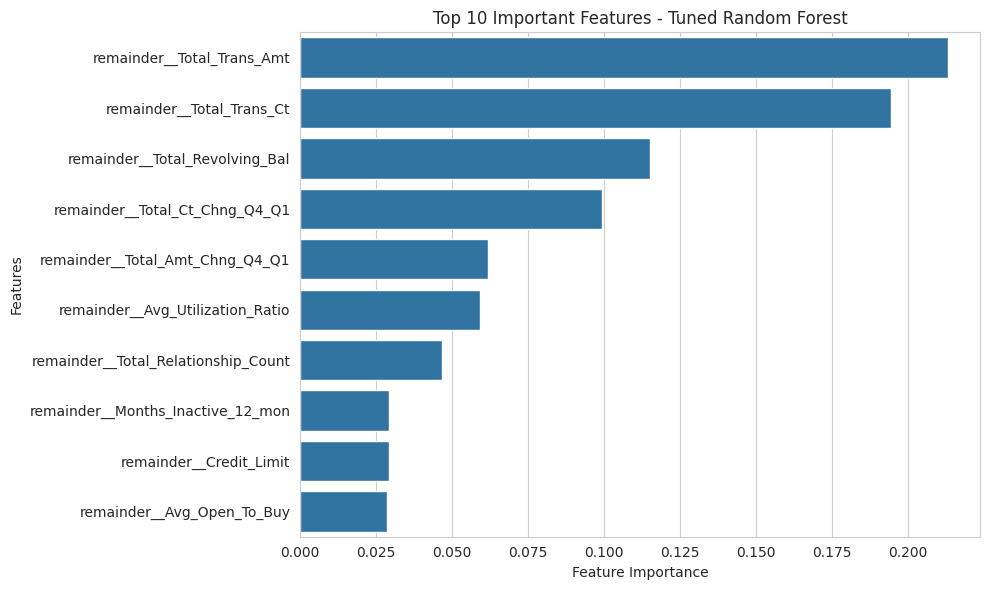

In [25]:

# Get feature names after one-hot encoding
feature_names = best_rf.named_steps['preprocessor'].get_feature_names_out()

# Extract feature importance scores
importances = best_rf.named_steps['classifier'].feature_importances_

# Create a DataFrame
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Display top 10 important features
display(feature_importance_df.head(10))

# Plot feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance_df.head(10),
    x='Importance',
    y='Feature'
)

plt.title('Top 10 Important Features - Tuned Random Forest')
plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()


### Observations:

1. Total_Trans_Amt is the most important feature, contributing approximately 21.30% of the total feature importance.
2. Total_Trans_Ct is the second most important feature, with an importance of 19.44%.
3. Total_Revolving_Bal ranks third, contributing approximately 11.51%.
4. Changes in transaction count and transaction amount also contribute significantly to churn prediction.
5. Overall, transaction-related features play a major role in the model's predictions.

### Interpretation:

The results indicate that customer transaction behaviour is highly influential in predicting credit card customer attrition. Monitoring transaction activity may help banks identify customers who are at risk of leaving.

Feature importance represents the model's reliance on each variable and does not establish a direct cause-and-effect relationship.

## Step 12: Conclusion

This project aimed to predict credit card customer attrition using machine learning techniques.

The dataset contained 10,127 customer records. Data cleaning, exploratory data analysis, outlier detection, and preprocessing were performed before model development.

Two machine learning algorithms, AdaBoost and Random Forest, were implemented and evaluated. Hyperparameter tuning was performed using GridSearchCV to optimize the Random Forest classifier.

### Final Results:

- Selected Model: Tuned Random Forest
- Accuracy: 95.41%
- Precision: 89.46%
- Recall: 80.92%
- F1-Score: 84.98%

The Tuned Random Forest achieved the best overall performance, particularly in identifying attrited customers.

Feature importance analysis revealed that Total_Trans_Amt, Total_Trans_Ct, and Total_Revolving_Bal were the most influential predictors.

The developed model demonstrates how machine learning can support customer retention analysis by identifying customers who may be at risk of leaving.

### Limitations:

1. The dataset contains fewer attrited customers than existing customers, resulting in class imbalance.
2. The model was evaluated using a single held-out test dataset.
3. Feature importance does not establish causal relationships.
4. Model performance on new customer populations may differ from the results obtained in this project.

### Future Improvements:

1. Evaluate additional machine learning algorithms such as XGBoost.
2. Explore class imbalance handling techniques such as SMOTE.
3. Perform further cross-validation and model calibration.
4. Test the model using newer customer data.
5. Develop a simple web application for customer churn prediction.

## Step 13: Final Confusion Matrix Visualization

A confusion matrix is used to evaluate the performance of the Tuned Random Forest model by comparing actual customer classes with predicted classes.

It helps identify correctly classified customers and prediction errors.

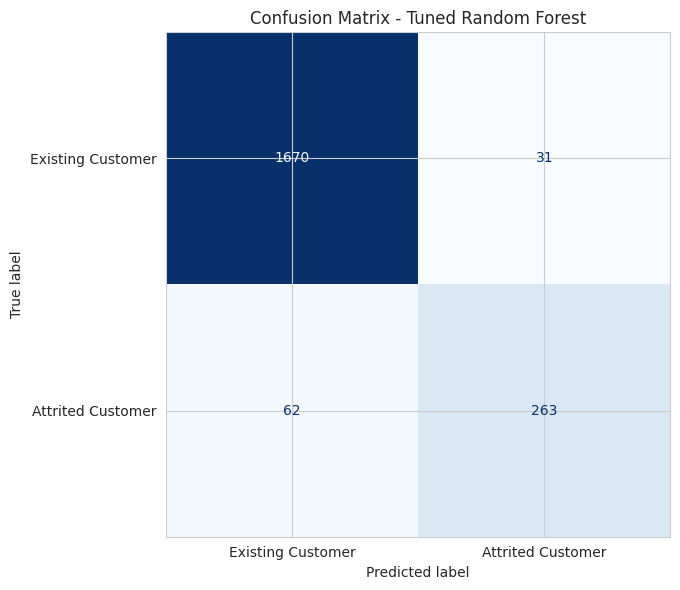

In [26]:

# Final Confusion Matrix - Tuned Random Forest

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, tuned_rf_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Existing Customer', 'Attrited Customer']
)

fig, ax = plt.subplots(figsize=(8, 6))

disp.plot(
    cmap='Blues',
    values_format='d',
    ax=ax,
    colorbar=False
)

plt.title('Confusion Matrix - Tuned Random Forest')
plt.tight_layout()
plt.show()


### Observations:

1. The model correctly predicted 1,670 Existing Customers.
2. It correctly identified 263 Attrited Customers.
3. A total of 31 Existing Customers were incorrectly predicted as Attrited.
4. A total of 62 Attrited Customers were incorrectly predicted as Existing.
5. The model achieved a recall of 80.92% for Attrited Customers.

### Interpretation:

The Tuned Random Forest successfully identified most of the customers who left the bank. However, 62 attrited customers were missed.

Reducing these false negatives could further improve the model's usefulness in customer retention strategies.

In [27]:

import joblib

joblib.dump(best_rf, 'credit_card_churn_model.pkl')

print("Final model saved successfully!")


Final model saved successfully!


In [28]:

from google.colab import files

files.download('credit_card_churn_model.pkl')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>